In [12]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 3.1.1


In [48]:
from IPython.display import HTML, display

In [13]:
from pathlib import Path

In [14]:
# Find the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define the dataset location
data_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

print("Dataset location:", data_path)
print("File exists:", data_path.exists())

Dataset location: /Users/temiloluwa/Documents/customer-intelligence-project/customer-purchase-intelligence/data/raw/online_retail_II.xlsx
File exists: True


In [15]:
excel_file = pd.ExcelFile(data_path)
print("Available worksheets:")
print(excel_file.sheet_names)

Available worksheets:
['Year 2009-2010', 'Year 2010-2011']


In [18]:
sheets = pd.read_excel(
    data_path,
    sheet_name=None,
    engine="openpyxl"
)

df = pd.concat(
    sheets.values(),
    ignore_index=True
)

In [19]:
print("Dataset shape:", df.shape)

Dataset shape: (1067371, 8)


In [20]:
display(df.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [35]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [25]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})


In [26]:
missing_values.round(2)

,Missing Count,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [67]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate rows percentage:", df.duplicated().mean() * 100)

print(
    "Negative quantities:",
    (df["Quantity"] < 0).sum()
)

print(
    "Negative quantities percentage:",
    (df["Quantity"] < 0).mean() * 100
)


print(
    "Zero or negative prices:",
    (df["Price"] <= 0).sum()
)

print(
    "Zero or negative prices percentage:",
    (df["Price"] <= 0).mean() * 100
)


print(
    "Missing customer IDs:",
    df["Customer ID"].isnull().sum(),
    
)

print(
    "Missing customer IDs Percentage: ", 
    (df["Customer ID"].isnull().mean() * 100).round(2)
)


Duplicate rows: 34335
Duplicate rows percentage: 3.2167821685243467
Negative quantities: 22950
Negative quantities percentage: 2.1501427338760375
Zero or negative prices: 6207
Zero or negative prices percentage: 0.5815222635803297
Missing customer IDs: 243007
Missing customer IDs Percentage:  22.77


In [34]:
print("First transaction:", df["InvoiceDate"].min())

print("Last transaction:", df["InvoiceDate"].max())

print(
    "Number of unique customers:",
    df["Customer ID"].nunique()
)

print(
    "Number of unique invoices:",
    df["Invoice"].nunique()
)

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00
Number of unique customers: 5942
Number of unique invoices: 53628


In [51]:
total_rows = len(df)
missing_cust_count = df['Customer ID'].isna().sum()
missing_cust_pct = (missing_cust_count / total_rows) * 100

duplicate_count = df.duplicated().sum()
duplicate_pct = (duplicate_count / total_rows) * 100


negative_qty_count = (df['Quantity'] < 0).sum() 
negative_qty_pct = (negative_qty_count / total_rows) * 100 

missing_desc_pct = (df['Description'].isna().sum() / total_rows) * 100 

In [54]:
html_content = f"""
<style>
    .metrics-container {{
        font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;
        color: #e5e7eb;
        background-color: #0f1117;
        padding: 20px;
        border-radius: 12px;
        max-width: 900px;
    }}
    .metrics-grid {{
        display: grid;
        grid-template-columns: repeat(2, 1fr);
        gap: 16px;
        margin-bottom: 16px;
    }}
    .metric-card {{
        background-color: #161b22;
        border: 1px solid #30363d;
        border-radius: 10px;
        padding: 20px;
    }}
    .metric-title {{
        font-size: 13px;
        color: #8b949e;
        margin-bottom: 8px;
        text-transform: uppercase;
        letter-spacing: 0.05em;
    }}
    .metric-value {{
        font-size: 28px;
        font-weight: 700;
        color: #f0f6fc;
        margin-bottom: 4px;
    }}
    .metric-subtitle {{
        font-size: 12px;
        color: #8b949e;
    }}
    .badge-success {{
        display: inline-block;
        background-color: #033a16;
        color: #3fb950;
        padding: 2px 8px;
        border-radius: 12px;
        font-size: 11px;
        font-weight: 600;
        margin-top: 6px;
    }}
    .card-full {{
        background-color: #161b22;
        border: 1px solid #30363d;
        border-radius: 10px;
        padding: 20px;
    }}
    .progress-row {{
        display: flex;
        align-items: center;
        margin-top: 12px;
        margin-bottom: 8px;
        font-size: 13px;
    }}
    .progress-label {{
        width: 120px;
        color: #c9d1d9;
    }}
    .progress-track {{
        flex-grow: 1;
        background-color: #30363d;
        height: 8px;
        border-radius: 4px;
        margin: 0 16px;
        overflow: hidden;
    }}
    .progress-fill {{
        background-color: #f78166;
        height: 100%;
        border-radius: 4px;
    }}
    .progress-pct {{
        width: 50px;
        text-align: right;
        color: #c9d1d9;
        font-weight: 600;
    }}
</style>

<div class="metrics-container">
    <h3 style="color: #f0f6fc; margin-top: 0; margin-bottom: 16px; font-size: 18px;">1. Interpreting your results</h3>
    
    <!-- Top 4 Cards Grid -->
    <div class="metrics-grid">
        <div class="metric-card">
            <div class="metric-title">Total transaction rows</div>
            <div class="metric-value">{total_rows:,}</div>
            <div class="badge-success">✓ Loaded correctly</div>
        </div>
        
        <div class="metric-card">
            <div class="metric-title">Missing customer IDs</div>
            <div class="metric-value">{missing_cust_pct:.2f}%</div>
            <div class="metric-subtitle">{missing_cust_count:,} rows</div>
        </div>
        
        <div class="metric-card">
            <div class="metric-title">Exact duplicate rows</div>
            <div class="metric-value">{duplicate_count:,}</div>
            <div class="metric-subtitle">{duplicate_pct:.2f}% of dataset</div>
        </div>
        
        <div class="metric-card">
            <div class="metric-title">Negative quantities</div>
            <div class="metric-value">{negative_qty_count:,}</div>
            <div class="metric-subtitle">{negative_qty_pct:.2f}% of dataset</div>
        </div>
    </div>
    
    <!-- Bottom Missing Values Breakdown Card -->
    <div class="card-full">
        <div class="metric-title" style="margin-bottom: 12px;">Missing values by column</div>
        
        <div class="progress-row">
            <div class="progress-label">Customer ID</div>
            <div class="progress-track">
                <div class="progress-fill" style="width: {missing_cust_pct}%;"></div>
            </div>
            <div class="progress-pct">{missing_cust_pct:.2f}%</div>
        </div>
        
        <div class="progress-row">
            <div class="progress-label">Description</div>
            <div class="progress-track">
                <div class="progress-fill" style="width: {missing_desc_pct}%;"></div>
            </div>
            <div class="progress-pct">{missing_desc_pct:.2f}%</div>
        </div>
        
        <div style="font-size: 12px; color: #8b949e; margin-top: 16px;">
            All six remaining columns have no missing values.
        </div>
    </div>
</div>
"""

display(HTML(html_content))

In [78]:

# Convert invoice identifiers to strings
invoice_str = df["Invoice"].astype("string").str.strip()

# Identify cancellation invoices
df["is_cancelled"] = invoice_str.str.upper().str.startswith(
    "C", na=False
)


print("Cancellation rows:", df["is_cancelled"].sum())

print(
    "Negative quantities:",
    (df["Quantity"] < 0).sum()
)

# Cross-tabulate cancellations against negative quantities
pd.crosstab(
    df["is_cancelled"],
    df["Quantity"] < 0,
    margins=True
)


Cancellation rows: 19494
Negative quantities: 22950


Quantity,False,True,All
is_cancelled,,,
False,1044420,3457,1047877
True,1,19493,19494
All,1044421,22950,1067371


In [87]:
display(
    df.loc[df["is_cancelled"] == True, ["Invoice", "StockCode", "Quantity"]].head(10)
)

,Invoice,StockCode,Quantity
178,C489449,22087,-12
179,C489449,85206A,-6
180,C489449,21895,-4
181,C489449,21896,-6
182,C489449,22083,-12
183,C489449,21871,-12
184,C489449,84946,-12
185,C489449,84970S,-24
186,C489449,22090,-12
196,C489459,90200A,-3


In [59]:

price_issues = df[df["Price"] <= 0]

display(
    price_issues[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price"
        ]
    ].head(20)
)

print("Zero prices:", (df["Price"] == 0).sum())
print("Negative prices:", (df["Price"] < 0).sum())


,Invoice,StockCode,Description,Quantity,Price
263,489464,21733,85123a mixed,-96,0.0
283,489463,71477,short,-240,0.0
284,489467,85123A,21733 mixed,-192,0.0
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3161,489659,21350,NaN,230,0.0
3162,489660,35956,lost,-1043,0.0
3168,489663,35605A,damages,-117,0.0
3731,489781,84292,NaN,17,0.0
4296,489806,18010,NaN,-770,0.0


Zero prices: 6202
Negative prices: 5


In [64]:

# Identify all rows belonging to exact duplicate groups
duplicate_groups = df[
    df.duplicated(
        subset=[
            "Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price",
            "Customer ID", "Country"
        ],
        keep=False
    )
]

display(
    len(duplicate_groups),
    duplicate_groups.sort_values(
        ["Invoice", "StockCode"]
    ).head(20)
)


67242

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelled
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,False
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,False
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,False


In [65]:

df["missing_customer"] = df["Customer ID"].isna()

pd.crosstab(
    df["missing_customer"],
    df["is_cancelled"],
    normalize="index"
).round(3)


is_cancelled,False,True
missing_customer,,
False,0.977,0.023
True,0.997,0.003


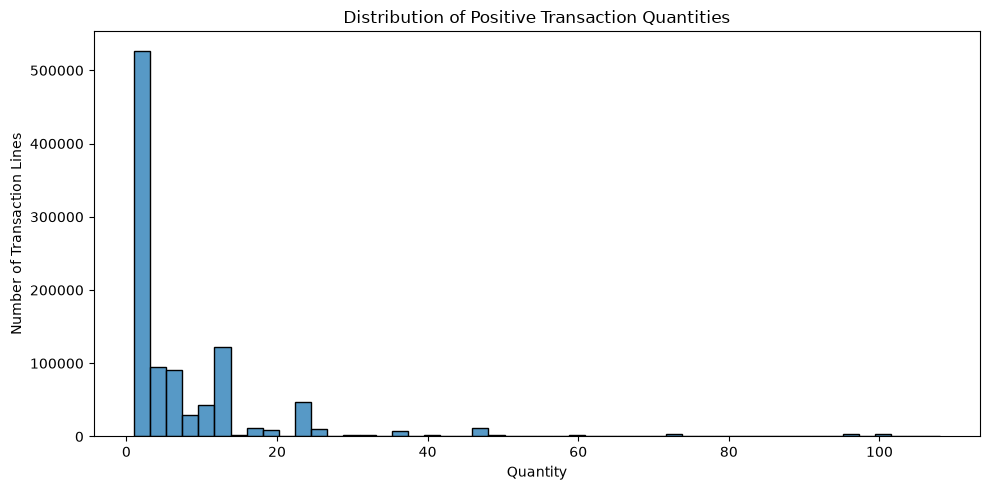

99th percentile: 108.0


In [66]:

# Focus on positive quantities
positive_quantities = df.loc[
    df["Quantity"] > 0, "Quantity"
]

# Limit visualized values to the 99th percentile
upper_limit = positive_quantities.quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    positive_quantities[
        positive_quantities <= upper_limit
    ],
    bins=50
)

plt.title("Distribution of Positive Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

print("99th percentile:", upper_limit)


In [104]:

# Keep the original dataset unchanged
standardized_df = df.copy()

# Standardize column names
standardized_df = standardized_df.rename(columns={
    "Invoice": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "unit_price",
    "Customer ID": "customer_id",
    "Country": "country"
})

# Convert identifiers to consistent string types
standardized_df["invoice_no"] = (
    standardized_df["invoice_no"].astype("string").str.strip()
)

standardized_df["customer_id"] = (
    standardized_df["customer_id"].astype("Int64").astype("string")
)

print("Original data:", df.dtypes)
print("Clean data:",standardized_df.dtypes)


Original data: Invoice                     object
StockCode                   object
Description                 object
Quantity                     int64
InvoiceDate         datetime64[us]
Price                      float64
Customer ID                float64
Country                        str
is_cancelled               boolean
missing_customer              bool
dtype: object
Clean data: invoice_no                  string
stock_code                  object
description                 object
quantity                     int64
invoice_date        datetime64[us]
unit_price                 float64
customer_id                 string
country                        str
is_cancelled               boolean
missing_customer              bool
dtype: object


In [105]:

# Define purchase eligibility conditions
has_customer = standardized_df["customer_id"].notna()
positive_quantity = standardized_df["quantity"] > 0
positive_price = standardized_df["unit_price"] > 0

not_cancelled = ~(
    standardized_df["invoice_no"].str.upper().str.startswith(
        "C", na=False
    )
)

# Combine all conditions
valid_purchase = (
    has_customer
    & positive_quantity
    & positive_price
    & not_cancelled
)

# Create a separate modeling dataset
purchases_df = standardized_df.loc[valid_purchase].copy()

# Calculate line-level revenue
purchases_df["line_revenue"] = (
    purchases_df["quantity"]
    * purchases_df["unit_price"]
)

print("Original rows:", len(standardized_df))
print("Eligible purchase rows:", len(purchases_df))

print(
    "Percentage retained:",
    round(len(purchases_df) / len(standardized_df) * 100, 2)
)


Original rows: 1067371
Eligible purchase rows: 805549
Percentage retained: 75.47


In [106]:
standardized_df

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,missing_customer
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False
...,...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,False,False
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,False,False
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,False,False
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,False,False


In [94]:
purchases_df

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,missing_customer,line_revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,30.00
...,...,...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,False,False,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,False,False,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,False,False,16.60
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,False,False,14.85


In [95]:

audit = pd.DataFrame({
    "Rule": [
        "Missing customer ID",
        "Non-positive quantity",
        "Non-positive price",
        "Cancellation invoice",
        "Eligible purchase rows"
    ],
    "Rows": [
        (~has_customer).sum(),
        (~positive_quantity).sum(),
        (~positive_price).sum(),
        (~not_cancelled).sum(),
        valid_purchase.sum()
    ]
})

display(audit)


,Rule,Rows
0,Missing customer ID,243007
1,Non-positive quantity,22950
2,Non-positive price,6207
3,Cancellation invoice,19494
4,Eligible purchase rows,805549


In [103]:

print("Unique customers:", purchases_df["customer_id"].nunique())

print("Unique invoices:", purchases_df["invoice_no"].nunique())

print("Total positive sales value:",
      round(purchases_df["line_revenue"].sum(), 2))

print("Earliest purchase:", purchases_df["invoice_date"].min())

print("Latest purchase:", purchases_df["invoice_date"].max())

display(purchases_df.head())


Unique customers: 5878
Unique invoices: 36969
Total positive sales value: 17743429.18
Earliest purchase: 2009-12-01 07:45:00
Latest purchase: 2011-12-09 12:50:00


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,missing_customer,line_revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,30.0


In [107]:

# Identify negative quantities without a C prefix
exceptions = df.loc[
    (df["Quantity"] < 0)
    & (~df["is_cancelled"])
].copy()

print("Number of exception rows:", len(exceptions))

print("\nMost common stock codes:")
display(exceptions["StockCode"].value_counts().head(15))

print("\nSample records:")
display(
    exceptions[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Customer ID"]
    ].head(20)
)


Number of exception rows: 3457

Most common stock codes:


StockCode
22423     12
46000M     6
82494L     6
22719      6
46000S     5
84016      5
85017A     5
47566B     5
20852      5
85175      5
21830      5
71477      4
21768      4
84559D     4
84990      4
Name: count, dtype: int64


Sample records:


,Invoice,StockCode,Description,Quantity,Price,Customer ID
263,489464,21733,85123a mixed,-96,0.0,NaN
283,489463,71477,short,-240,0.0,NaN
284,489467,85123A,21733 mixed,-192,0.0,NaN
470,489521,21646,NaN,-50,0.0,NaN
3114,489655,20683,NaN,-44,0.0,NaN
3162,489660,35956,lost,-1043,0.0,NaN
3168,489663,35605A,damages,-117,0.0,NaN
4296,489806,18010,NaN,-770,0.0,NaN
4538,489820,21133,invcd as 84879?,-720,0.0,NaN
4566,489821,85049G,NaN,-240,0.0,NaN


In [109]:

invoice_customer_counts = (
    purchases_df
    .groupby("invoice_no")["customer_id"]
    .nunique()
)

print(
    "Invoices linked to multiple customers:",
    (invoice_customer_counts > 1).sum()
)

display(
    invoice_customer_counts[
        invoice_customer_counts > 1
    ].head(10)
)


Invoices linked to multiple customers: 0


Series([], Name: customer_id, dtype: int64)

In [110]:

print("Total exception rows:", len(exceptions))

print(
    "Exceptions with zero price:",
    (exceptions["Price"] == 0).sum()
)

print(
    "Exceptions with missing customer ID:",
    exceptions["Customer ID"].isna().sum()
)

print(
    "Exceptions with positive price:",
    (exceptions["Price"] > 0).sum()
)

print(
    "Exceptions with both positive price and customer ID:",
    (
        (exceptions["Price"] > 0)
        & exceptions["Customer ID"].notna()
    ).sum()
)


Total exception rows: 3457
Exceptions with zero price: 3457
Exceptions with missing customer ID: 3457
Exceptions with positive price: 0
Exceptions with both positive price and customer ID: 0


In [111]:

invoice_dates = (
    purchases_df
    .groupby("invoice_no")["invoice_date"]
    .nunique()
)

print(
    "Invoices with multiple timestamps:",
    (invoice_dates > 1).sum()
)

display(
    invoice_dates[invoice_dates > 1].head(10)
)


Invoices with multiple timestamps: 64


invoice_no
492807    2
499967    2
500353    2
501618    2
501871    2
503609    2
505791    2
509851    2
510644    2
513813    2
Name: invoice_date, dtype: int64

In [112]:

invoice_time_check = (
    purchases_df
    .groupby("invoice_no")
    .agg(
        first_timestamp=("invoice_date", "min"),
        last_timestamp=("invoice_date", "max"),
        unique_timestamps=("invoice_date", "nunique"),
        customer_count=("customer_id", "nunique")
    )
)

invoice_time_check["time_difference"] = (
    invoice_time_check["last_timestamp"]
    - invoice_time_check["first_timestamp"]
)

multiple_timestamps = invoice_time_check[
    invoice_time_check["unique_timestamps"] > 1
].copy()

display(
    multiple_timestamps
    .sort_values("time_difference", ascending=False)
    .head(20)
)


,first_timestamp,last_timestamp,unique_timestamps,customer_count,time_difference
invoice_no,,,,,
521901,2010-09-09 12:35:00,2010-09-09 12:37:00,2,1,0 days 00:02:00
492807,2009-12-20 12:28:00,2009-12-20 12:29:00,2,1,0 days 00:01:00
534948,2010-11-24 15:31:00,2010-11-24 15:32:00,2,1,0 days 00:01:00
540185,2011-01-05 13:40:00,2011-01-05 13:41:00,2,1,0 days 00:01:00
541596,2011-01-19 16:18:00,2011-01-19 16:19:00,2,1,0 days 00:01:00
541631,2011-01-20 10:47:00,2011-01-20 10:48:00,2,1,0 days 00:01:00
541816,2011-01-21 15:56:00,2011-01-21 15:57:00,2,1,0 days 00:01:00
541849,2011-01-23 13:33:00,2011-01-23 13:34:00,2,1,0 days 00:01:00
542217,2011-01-26 12:35:00,2011-01-26 12:36:00,2,1,0 days 00:01:00


In [113]:

multiple_timestamps["different_days"] = (
    multiple_timestamps["first_timestamp"].dt.normalize()
    != multiple_timestamps["last_timestamp"].dt.normalize()
)

print(
    "Invoices spanning multiple calendar days:",
    multiple_timestamps["different_days"].sum()
)

print(
    "Largest timestamp difference:",
    multiple_timestamps["time_difference"].max()
)


Invoices spanning multiple calendar days: 0
Largest timestamp difference: 0 days 00:02:00


In [116]:
print(purchases_df.dtypes)


invoice_no                  string
stock_code                  object
description                 object
quantity                     int64
invoice_date        datetime64[us]
unit_price                 float64
customer_id                 string
country                        str
is_cancelled               boolean
missing_customer              bool
line_revenue               float64
dtype: object


In [117]:

print(
    purchases_df["stock_code"]
    .map(lambda x: type(x).__name__)
    .value_counts()
)

print(
    purchases_df["description"]
    .map(lambda x: type(x).__name__)
    .value_counts()
)


stock_code
int    713989
str     91560
Name: count, dtype: int64
description
str    805549
Name: count, dtype: int64


In [118]:

purchases_df["stock_code"] = (
    purchases_df["stock_code"]
    .astype("string")
    .str.strip()
)

purchases_df["description"] = (
    purchases_df["description"]
    .astype("string")
    .str.strip()
)

print(purchases_df.dtypes)


invoice_no                  string
stock_code                  string
description                 string
quantity                     int64
invoice_date        datetime64[us]
unit_price                 float64
customer_id                 string
country                        str
is_cancelled               boolean
missing_customer              bool
line_revenue               float64
dtype: object


In [119]:
from pathlib import Path
# Locate project root
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
# Create output directory
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
# Save eligible purchase records
purchases_df.to_parquet(
    output_dir / "eligible_purchases.parquet",
    index=False
)
print("Dataset saved successfully!")
print("Shape:", purchases_df.shape)


Dataset saved successfully!
Shape: (805549, 11)


In [120]:

saved_df = pd.read_parquet(
    output_dir / "eligible_purchases.parquet"
)

print("Saved rows:", len(saved_df))
print("Original rows:", len(purchases_df))

print("Data matches:", saved_df.equals(purchases_df))


Saved rows: 805549
Original rows: 805549
Data matches: False


In [121]:

from pandas.testing import assert_frame_equal

# Reset the original index to match the Parquet file
original_reset = purchases_df.reset_index(drop=True)
saved_reset = saved_df.reset_index(drop=True)

try:
    assert_frame_equal(
        original_reset,
        saved_reset
    )
    print("SUCCESS: All data, indexes and data types match!")

except AssertionError as e:
    print("Differences still exist:")
    print(str(e)[:1500])


SUCCESS: All data, indexes and data types match!


In [122]:

purchases_df = purchases_df.reset_index(drop=True)

purchases_df.to_parquet(
    output_dir / "eligible_purchases.parquet",
    index=False
)

print("Final dataset shape:", purchases_df.shape)
print("File saved successfully!")


Final dataset shape: (805549, 11)
File saved successfully!
